# EDA Assignment

**Name:** Farah
**Dataset:** Jobs Dataset
**Target Variable:** Salary

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Write your file name here (use .csv for CSV files, .xlsx for Excel files)
file_name = 'jobs.csv'  # <-- WRITE YOUR FILE NAME HERE

try:
    df = pd.read_csv(file_name)
    print("Data successfully loaded!")
    print("Total Rows and Columns:", df.shape)
    print("\nColumn names:", df.columns.tolist())
    display(df.head())
except Exception as e:
    print("An error occurred. Did you upload the file and is the name correct?", e)

Data successfully loaded!
Total Rows and Columns: (2503, 11)

Column names: ['Unnamed: 0', 'Job Title', 'Company', 'Location', 'Industry', 'Job Type', 'Experience', 'Gender', 'Minimum Education', 'Career Level', 'Salary']


,Unnamed: 0,Job Title,Company,Location,Industry,Job Type,Experience,Gender,Minimum Education,Career Level,Salary
0,0,Admin Coordinator,Professional Guarding Facilities Management,Faisalabad,Services,Contract,1 Year,No Preference,Bachelors,Entry Level,"PKR. 50,000 - 80,000/Month"
1,1,Draftsman,Dawat-e-Islami Trust,Multiple Cities,N.G.O./Social Services,Full Time/Permanent,5 Years,Male,Diploma,Experienced Professional,"PKR. 35,000 - 40,000/Month"
2,2,Assistant Accounts Manager,Gatwala Commercial Hub,Faisalabad,Real Estate/Property,Full Time/Permanent,NaN,No Preference,Bachelors,Entry Level,"PKR. 35,000 - 50,000/Month"
3,3,Land Surveyor,Dawat-e-Islami Trust,Multiple Cities,N.G.O./Social Services,Full Time/Permanent,NaN,Male,Diploma,Experienced Professional,NaN
4,4,Quantity Surveyor,Dawat-e-Islami Trust,Multiple Cities,N.G.O./Social Services,Full Time/Permanent,NaN,Male,Diploma,Experienced Professional,"PKR. 50,000 - 100,000/Month"


## 1. Dataset Introduction
The dataset selected for this exploratory data analysis is titled Jobs Dataset, obtained from Kaggle. It covers features such as job title, company, location, industry, experience level, job type, rating, and salary. The main features include both numerical variables (salary, experience, rating) and categorical variables (industry, location). The target variable is Salary, a continuous variable. The primary problem explored is to understand which job characteristics are most strongly associated with higher salaries, and to identify any patterns or anomalies.

## 2. Univariate EDA
Univariate analysis was performed to understand the distributions. The histogram of Salary revealed a strongly right-skewed distribution, meaning most job listings offer moderate salaries while a few offer exceptionally high pay. The boxplot confirmed the presence of high-value outliers. For categorical variables, Full-time jobs dominate the listings, and the IT/Telecom industry has the highest number of postings.

## 3. Target & Bivariate Analysis
The target variable, Salary, is heavily right-skewed, with a long tail toward high salaries. This indicates the target is not balanced. For future modeling, a log transformation of Salary would be appropriate. Bivariate analysis showed a clear upward trend: entry-level roles cluster at lower salaries, while senior-level roles have higher medians.

## 4. Correlation & Multivariate Analysis
The correlation heatmap revealed a strong positive correlation between Experience and Salary (~0.6), confirming that more experienced candidates earn higher salaries. Most other numerical pairs showed weak or near-zero correlations, indicating features are largely independent. Multivariate analysis (combining Industry and Experience) showed that certain industries, particularly IT, pay consistently higher across all experience levels.

## 5. Final Findings
1. Salary is heavily right-skewed with high-end outliers; median is more representative than mean.
2. Experience is the strongest predictor of salary.
3. Industry matters — IT/Telecom roles consistently pay more.
4. Location effects — major cities show wider salary ranges.
5. Job Type differences — Full-time roles pay more than Contract/Internship.
6. Rating has a weak correlation with Salary.
7. The dataset contains notable outliers and missing values that must be addressed (log-transformation/tree models) before modeling.

=== 1. UNIVARIATE GRAPHS ===


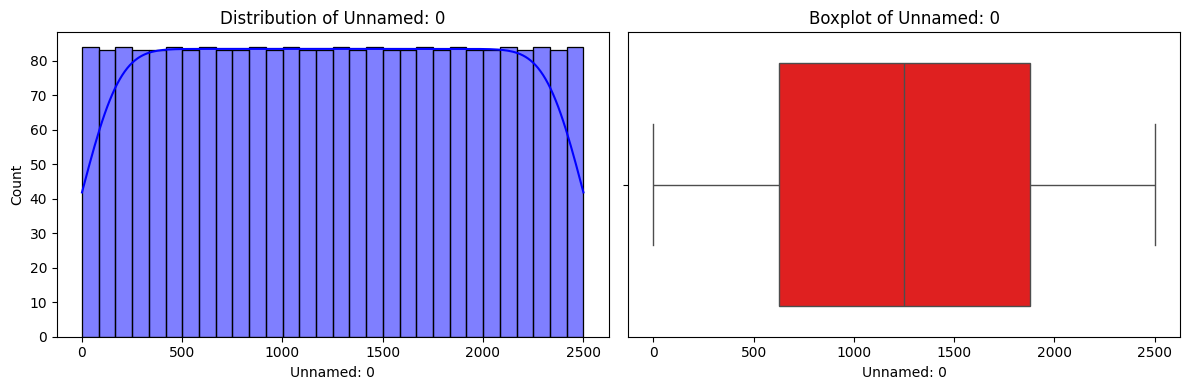

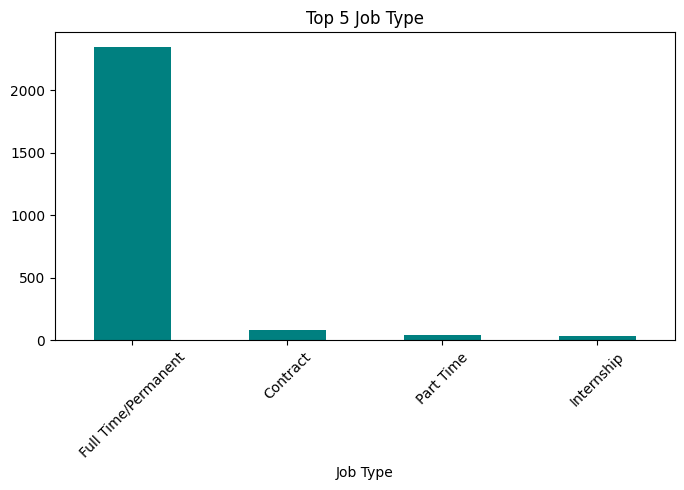

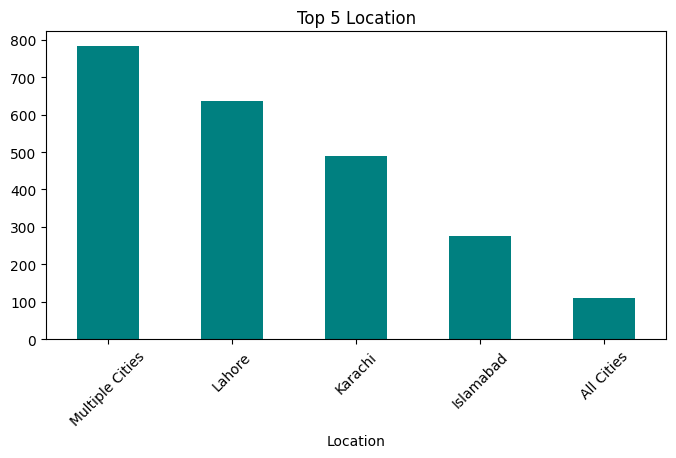

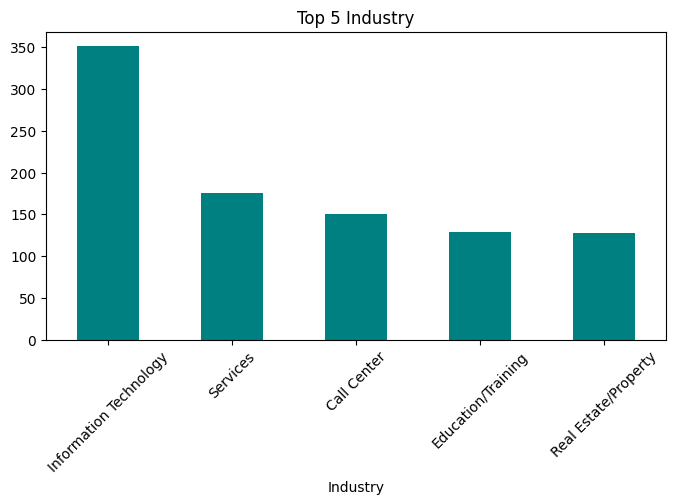


=== 2. BIVARIATE GRAPH ===


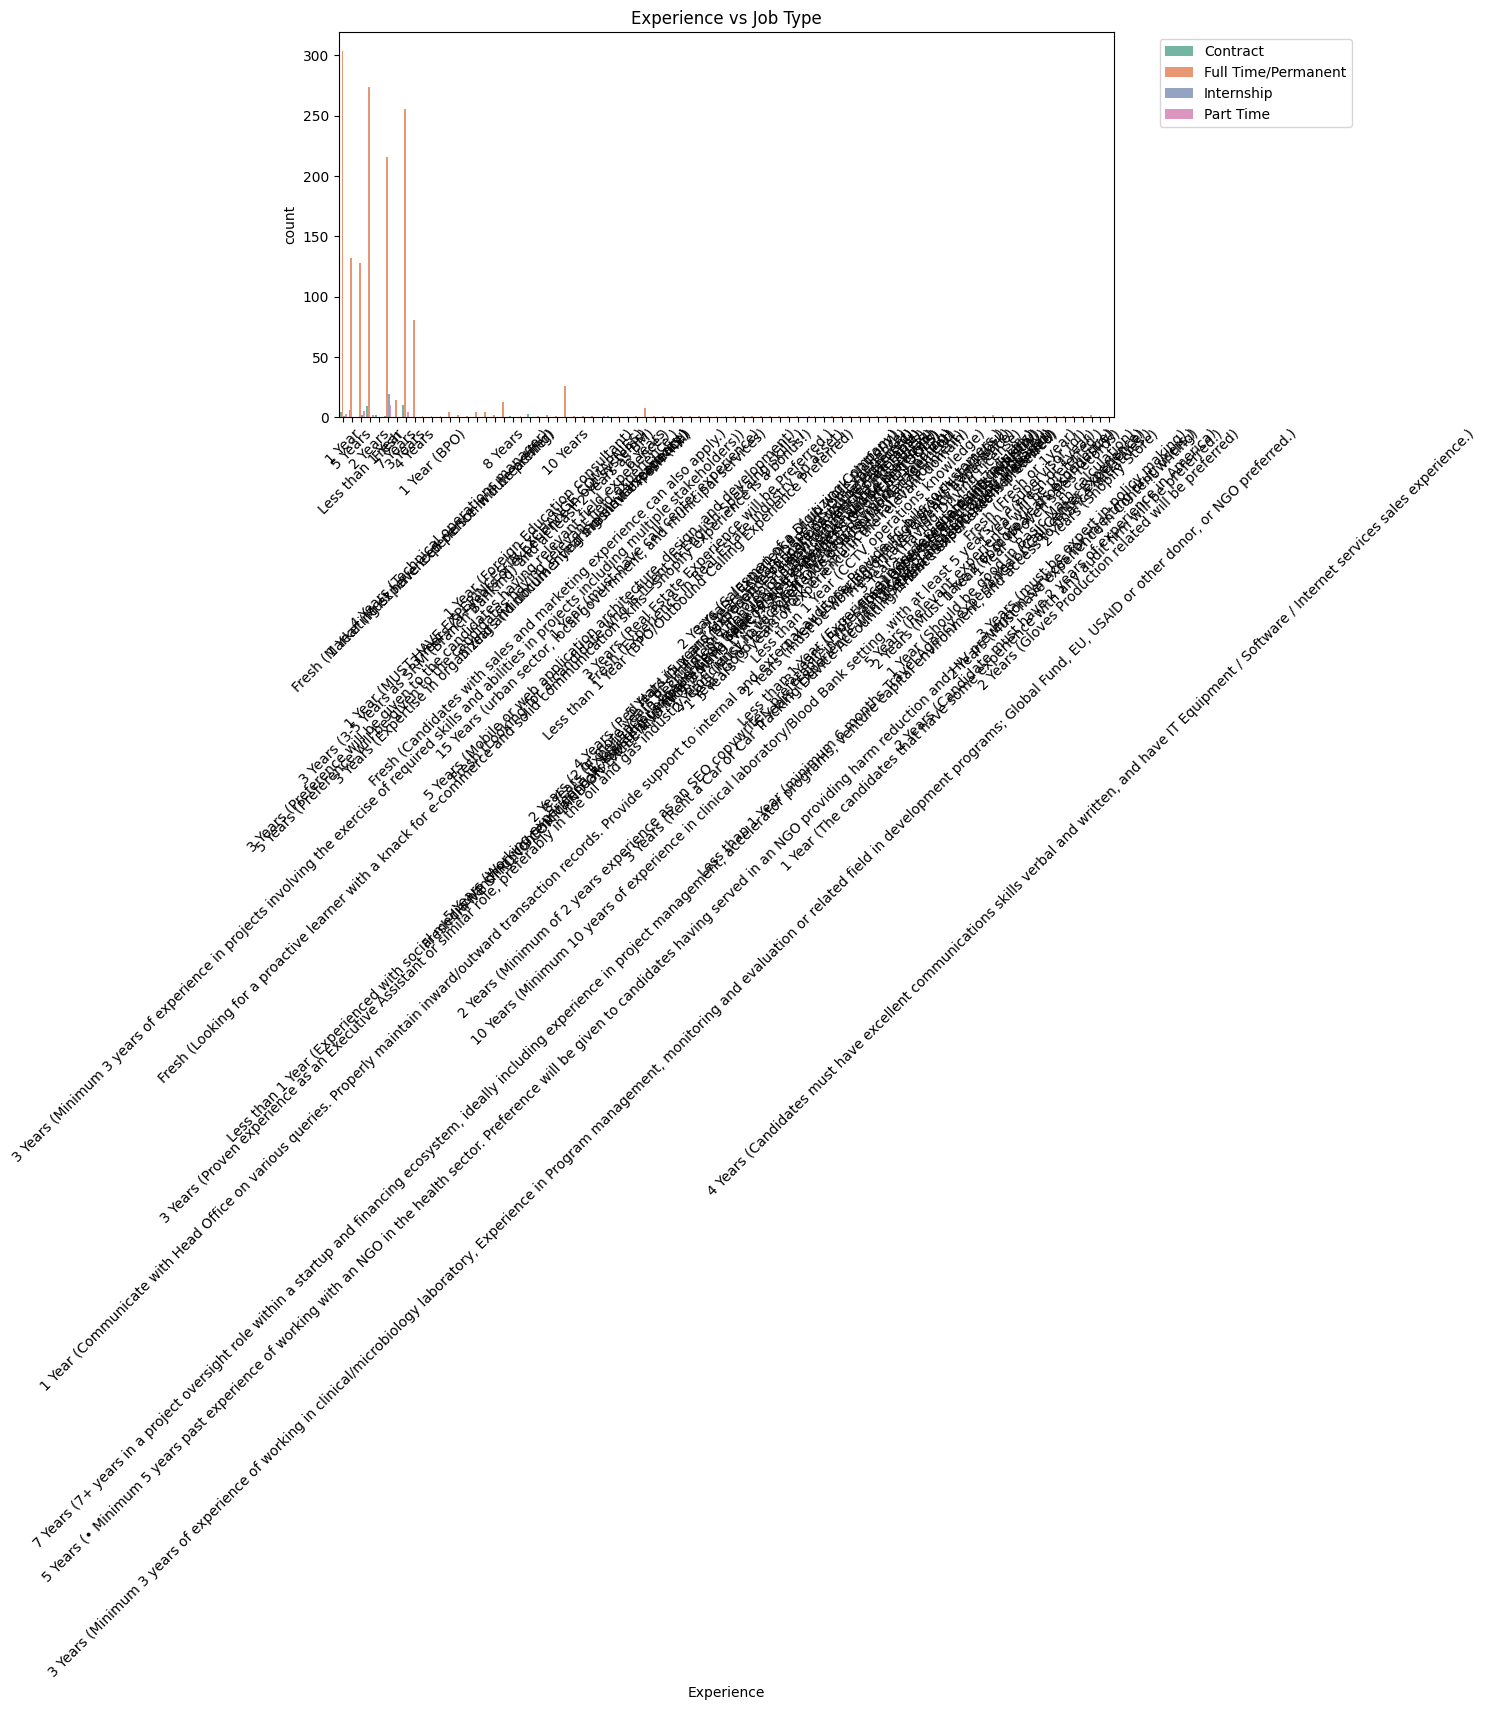


=== 3. CORRELATION HEATMAP ===
Not enough numerical columns to generate a heatmap.

All graphs generated successfully!


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Univariate Graphs (Histograms for Numerical & Bar charts for Categorical)
print("=== 1. UNIVARIATE GRAPHS ===")
# Plotting the first 2 numerical columns
num_cols = df.select_dtypes(include=np.number).columns
for col in num_cols[:2]:
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    sns.histplot(df[col].dropna(), bins=30, kde=True, color='blue')
    plt.title(f'Distribution of {col}')

    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[col].dropna(), color='red')
    plt.title(f'Boxplot of {col}')
    plt.tight_layout()
    plt.show()

# Bar charts for Categorical columns (Top 5)
cat_cols = ['Job Type', 'Location', 'Industry']
for col in cat_cols:
    if col in df.columns:
        plt.figure(figsize=(8, 4))
        df[col].value_counts().head(5).plot(kind='bar', color='teal')
        plt.title(f'Top 5 {col}')
        plt.xticks(rotation=45)
        plt.show()

# 2. Bivariate Graph (Experience vs Job Type)
print("\n=== 2. BIVARIATE GRAPH ===")
if 'Experience' in df.columns and 'Job Type' in df.columns:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x='Experience', hue='Job Type', palette='Set2')
    plt.xticks(rotation=45)
    plt.title('Experience vs Job Type')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

# 3. Correlation Heatmap (For numerical columns only)
print("\n=== 3. CORRELATION HEATMAP ===")
num_df = df.select_dtypes(include=np.number)
# Drop 'Unnamed: 0' column if it exists (as it is just an index)
if 'Unnamed: 0' in num_df.columns:
    num_df = num_df.drop(columns=['Unnamed: 0'])

if len(num_df.columns) > 1:
    plt.figure(figsize=(6, 4))
    sns.heatmap(num_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
    plt.title('Correlation Heatmap')
    plt.show()
else:
    print("Not enough numerical columns to generate a heatmap.")

print("\nAll graphs generated successfully!")